In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import classification_report
from sklearn.preprocessing import label_binarize

from sentence_transformers import SentenceTransformer
import umap.umap_ as umap

import gc
import torch

device = "cuda:1" if torch.cuda.is_available() else "cpu"



In [ ]:
def data_preprocessing(data,nmbr_of_features):
    if nmbr_of_features==6:
        data = data.drop(columns=['Study3', 'Study7', 'Study9'])
    elif nmbr_of_features==7:
        data = data.drop(columns=['Study2', 'Study3'])
        
    study_cols = [col for col in data.columns if "Study" in col]

    # Sort them by the number in the name (3, 5 -> maintains order)
    study_cols_sorted = sorted(study_cols, 
                            key=lambda x: int(x.split()[-1]))

    # Create mapping: Study 3 -> 0, Study 5 -> 1
    label_map = {col: i for i, col in enumerate(study_cols_sorted)}

    data = data.melt(value_vars=study_cols, var_name="study", value_name="text")


    data["label"] = data["study"].map(label_map)
    data = data.dropna(subset=["text"]).reset_index(drop=True)

    sentences=np.array(data["text"])
    print("Sentences shape:", np.shape(sentences))

    labels=np.array(data["label"])
    print("Labels shape:", np.shape(labels), "Unique labels:", np.unique(labels,return_counts=True))

    return sentences, labels

In [ ]:
def get_embeddings(sentences, model_name, device="cpu"):
    model = SentenceTransformer(model_name, device=device)
    embeddings = model.encode(sentences, show_progress_bar=True)
    print("Embeddings shape:", np.shape(embeddings))
    return embeddings

In [ ]:
def dimension_reduction_and_classif(X_train,X_test, y_train, y_test,number_of_features):
     
    umap = umap.UMAP(n_components=number_of_features, random_state=42)
    X_train = umap.fit_transform(X_train)
    X_test = umap.transform(X_test)


    svm = SVC(kernel='linear', probability=True)
    svm.fit(X_train, y_train)
    y_pred_svm = svm.predict(X_test)
    y_proba_svm = svm.predict_proba(X_test)

    acc_svm = balanced_accuracy_score(y_test, y_pred_svm)
    report_svm = classification_report(y_test, y_pred_svm, output_dict=True)

    
    y_test_bin = label_binarize(y_test, classes=classes)
    auc_svm = roc_auc_score(y_test_bin, y_proba_svm, multi_class="ovr", average="weighted")

    return acc_svm, report_svm, auc_svm
    

In [ ]:
data_type="cleanedversion2"
number_of_studies=9
sentences,labels = data_preprocessing(pd.read_excel("verbal_reports_processed.xlsx", sheet_name="cleanedversion2"),number_of_studies)

In [ ]:
models_to_try = [
    
    "stsb-roberta-large",
    "all-mpnet-base-v2",
    "sentence-t5-xl",
    "gtr-t5-large",
    "all-roberta-large-v1",
    'sentence-t5-xxl',
    'gtr-t5-xxl',
    "all-mpnet-base-v1",
    "all-MiniLM-L6-v2",
    "all-MiniLM-L12-v1",
    "multi-qa-mpnet-base-dot-v1"

]

In [ ]:

results = []

number_of_features=20

for model_name in models_to_try:
    
    embeddings = get_embeddings(sentences, model_name, device=device)

    # Cross-validation
    sss = StratifiedShuffleSplit(n_splits=100, test_size=0.2, random_state=42)
    sss.get_n_splits(embeddings)


    for i, (train_index, test_index) in enumerate(sss.split(embeddings, labels)):

        X_train, X_test = embeddings[train_index], embeddings[test_index]
        y_train, y_test = labels[train_index], labels[test_index]

        classes = sorted(list(set(y_train) | set(y_test)))
    
        acc_svm, report_svm, auc_svm = dimension_reduction_and_classif(X_train,X_test, y_train, y_test,number_of_features)
   
        results.append({
            "Model": model_name,
            "Classifier": f"SVM ({number_of_features} feature)",
            "Accuracy": acc_svm,
            "Precision": report_svm["weighted avg"]["precision"],
            "Recall": report_svm["weighted avg"]["recall"],
            "F1": report_svm["weighted avg"]["f1-score"],
            "AUC": auc_svm,
            "Fold": i
        })

   
    del model
    del embeddings
    torch.cuda.empty_cache() 
    gc.collect()              


df_results = pd.DataFrame(results)

df_results.to_csv(f"{data_type}_{number_of_studies}_studies.csv", index=False)

print("\n Results saved to '{data_type}_{number_of_studies}_studies.csv'.")



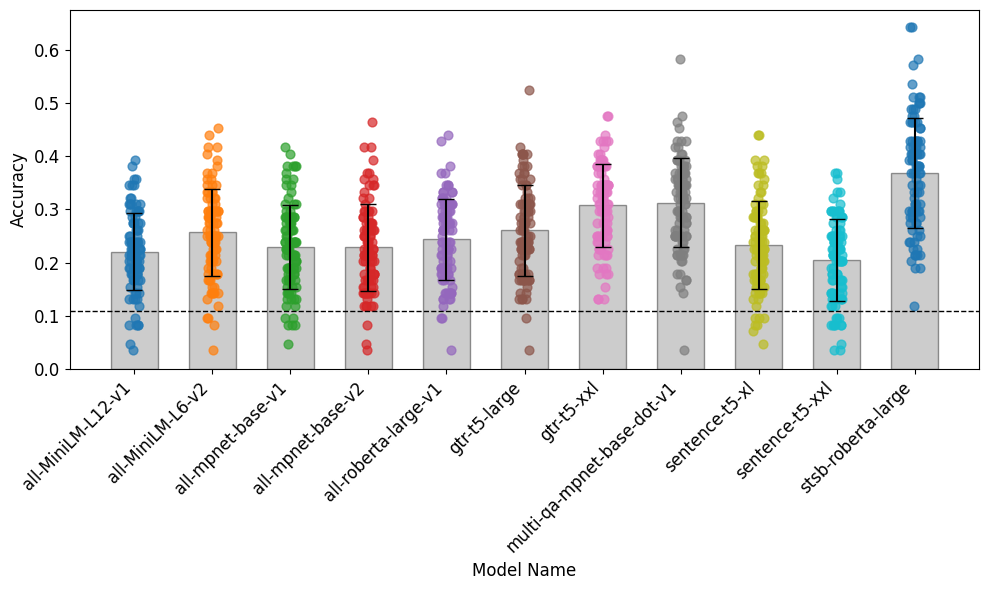

In [ ]:
# --- FILTER ONLY SVM WITH 20 FEATURES ---
svm_df = df_results[(df_results["Classifier"] == "SVM (20 feature)")]

# --- GROUP BY STUDY (MODEL) ---
grouped = svm_df.groupby("Model")

models = list(grouped.groups.keys())
means = grouped["Accuracy"].mean()
stds = grouped["Accuracy"].std()

# --- BAR PLOT ---
plt.figure(figsize=(10, 6))
x = np.arange(len(models))
bar_width = 0.6

plt.bar(x, means, yerr=stds, width=bar_width,
        alpha=0.4, color="gray", edgecolor="black", linewidth=1,
        capsize=6)

# --- ADD EACH FOLD AS JITTERED POINTS ---
for i, model in enumerate(models):
    values = grouped.get_group(model)["Accuracy"].values

    # jitter for the points
    jitter = (np.random.rand(len(values)) - 0.5) * 0.15  

    plt.scatter(np.full(len(values), x[i]) + jitter,
                values,
                s=40, alpha=0.7)


plt.axhline(y=0.11, color='black', linestyle='--', linewidth=1)
plt.xticks(x, models, rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xlabel("Model Name", fontsize=12)


plt.tight_layout()
plt.show()


In [ ]:
df_results.groupby(["Model", "Classifier"]).mean()